# Multi-Agent Workflow Planner for a Startup Accelerator

**Course-end project:** a LangGraph system in which three role-based agents (**Research Agent**,
**Funding Advisor**, **Pitch Coach**) work together, using a shared vector memory and peer
feedback loops, to turn a startup domain (for example *fintech* or *healthtech*) into a
founder-ready pitch deck outline.

**What this notebook shows**
1. Agent roles and responsibilities, scoped so they don't overlap
2. A LangGraph workflow with a planner, the three agents, two feedback loops and a final step
3. A shared vector memory the agents use to hand context to each other
4. Structured local trace logging (JSONL), with optional LangSmith tracing
5. Reasoning-trace visuals: the workflow graph, an agent swimlane timeline, a memory hand-off
   table and a written narrative of how the outline was produced

See `README.md` for the architecture, the rationale and the trade-offs.

## 1. Setup
Install the dependencies (run once). Then copy `.env.example` to `.env` and fill in the
course lab's Azure OpenAI values.

In [21]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [22]:
import os
import json
import time
import zlib
import operator
from pathlib import Path
from datetime import datetime, timezone
from typing import Literal, Optional, TypedDict

import numpy as np
import requests
from dotenv import load_dotenv
from pydantic import BaseModel, Field

load_dotenv()


def env(*names, default=None):
    """Return the first environment variable that is set (supports both the
    LangChain-style AZURE_OPENAI_* names and the LiteLLM/CrewAI-style AZURE_API_* names)."""
    for name in names:
        value = os.getenv(name)
        if value:
            return value
    return default


AZURE_ENDPOINT = env("AZURE_OPENAI_ENDPOINT", "AZURE_API_BASE")
AZURE_API_KEY = env("AZURE_OPENAI_API_KEY", "AZURE_API_KEY")
AZURE_API_VERSION = env("OPENAI_API_VERSION", "AZURE_OPENAI_API_VERSION", "AZURE_API_VERSION")
CHAT_DEPLOYMENT = env("AZURE_CHAT_DEPLOYMENT", default="gpt-5-mini")
EMBED_DEPLOYMENT = env("AZURE_EMBEDDING_DEPLOYMENT")      # optional
TAVILY_API_KEY = env("TAVILY_API_KEY")                    # optional

missing = [n for n, v in {"AZURE_OPENAI_ENDPOINT": AZURE_ENDPOINT,
                          "AZURE_OPENAI_API_KEY": AZURE_API_KEY,
                          "OPENAI_API_VERSION": AZURE_API_VERSION}.items() if not v]
if missing:
    raise EnvironmentError(f"Missing settings in .env: {', '.join(missing)}")

# Optional LangSmith tracing: only switched on when a key is present.
if env("LANGSMITH_API_KEY", "LANGCHAIN_API_KEY"):
    os.environ.setdefault("LANGSMITH_TRACING", "true")
    os.environ.setdefault("LANGCHAIN_TRACING_V2", "true")
    os.environ.setdefault("LANGSMITH_PROJECT", "startup-accelerator-agents")

print(f"Chat deployment : {CHAT_DEPLOYMENT}")
print(f"Embeddings      : {EMBED_DEPLOYMENT or 'local hashing embeddings (no Azure embedding deployment set)'}")
print(f"Web search      : {'Tavily' if TAVILY_API_KEY else 'off (agents use model knowledge and flag it)'}")
print(f"LangSmith       : {'on' if os.getenv('LANGSMITH_TRACING') == 'true' else 'off (local JSONL tracing only)'}")

Chat deployment : gpt-5-mini
Embeddings      : local hashing embeddings (no Azure embedding deployment set)
Web search      : off (agents use model knowledge and flag it)
LangSmith       : off (local JSONL tracing only)


In [23]:
from langchain_openai import AzureChatOpenAI
from langgraph.graph import StateGraph, START, END

# No temperature argument: gpt-5-family deployments only accept the default value.
llm = AzureChatOpenAI(
    azure_deployment=CHAT_DEPLOYMENT,
    azure_endpoint=AZURE_ENDPOINT,
    api_key=AZURE_API_KEY,
    api_version=AZURE_API_VERSION,
)

embedder = None
if EMBED_DEPLOYMENT:
    from langchain_openai import AzureOpenAIEmbeddings
    embedder = AzureOpenAIEmbeddings(
        azure_deployment=EMBED_DEPLOYMENT,
        azure_endpoint=AZURE_ENDPOINT,
        api_key=AZURE_API_KEY,
        api_version=AZURE_API_VERSION,
    )

## 2. Agent roles and responsibilities
Each agent owns one kind of output and is told explicitly what it must **not** do, so the
responsibilities don't overlap. A lightweight **Planner** (orchestrator) sets the agenda,
and the graph's router functions decide who works next.

In [24]:
ROLES = {
    "Planner": {
        "goal": "Turn the founder's domain into a work plan for the team.",
        "owns": "Research questions, funding questions, pitch requirements, success criteria",
        "does_not": "Produce market facts, funding advice or slides",
    },
    "Research Agent": {
        "goal": "Gather domain-specific market trends and insights.",
        "owns": "Market trends, target customers, competitors, risks, open questions",
        "does_not": "Recommend funding sources or write slides",
    },
    "Funding Advisor": {
        "goal": "Recommend grants and funding programs that fit the startup's domain and stage.",
        "owns": "Funding stage, ranked funding options, funding narrative, questions back to Research",
        "does_not": "Generate market data (asks Research instead) or write slides",
    },
    "Pitch Coach": {
        "goal": "Synthesize research and funding input into a compelling pitch deck outline.",
        "owns": "Slide-by-slide outline, one-line pitch, gaps in the inputs",
        "does_not": "Introduce new market facts or funding programs not supplied by peers",
    },
}

for name, r in ROLES.items():
    print(f"{name}\n  Goal     : {r['goal']}\n  Owns     : {r['owns']}\n  Does not : {r['does_not']}\n")

GUARDRAILS = (
    "Accuracy rules: Do not invent statistics, program names, URLs or quotes. "
    "Use figures only if they appear in the provided web results or peer input, and cite the URL. "
    "Anything from your own general knowledge must be labelled 'model knowledge - verify'. "
    "If you are unsure, say so. Funding programs change often: always tell the founder to verify "
    "eligibility, amounts and deadlines with the program itself."
)

Planner
  Goal     : Turn the founder's domain into a work plan for the team.
  Owns     : Research questions, funding questions, pitch requirements, success criteria
  Does not : Produce market facts, funding advice or slides

Research Agent
  Goal     : Gather domain-specific market trends and insights.
  Owns     : Market trends, target customers, competitors, risks, open questions
  Does not : Recommend funding sources or write slides

Funding Advisor
  Goal     : Recommend grants and funding programs that fit the startup's domain and stage.
  Owns     : Funding stage, ranked funding options, funding narrative, questions back to Research
  Does not : Generate market data (asks Research instead) or write slides

Pitch Coach
  Goal     : Synthesize research and funding input into a compelling pitch deck outline.
  Owns     : Slide-by-slide outline, one-line pitch, gaps in the inputs
  Does not : Introduce new market facts or funding programs not supplied by peers



## 3. Output schemas
Every agent returns structured output (Pydantic). This makes hand-offs between agents
reliable and gives each agent a `reasoning` field, a short summary the model writes of why
it produced its answer, which is captured in the trace log.

In [25]:
Confidence = Literal["high", "medium", "low"]


class WorkPlan(BaseModel):
    domain_framing: str = Field(description="One-paragraph framing of the domain for the team")
    research_questions: list[str] = Field(description="3-5 questions for the Research Agent")
    funding_questions: list[str] = Field(description="2-4 questions for the Funding Advisor")
    pitch_requirements: list[str] = Field(description="What the final pitch outline must cover")
    success_criteria: list[str] = Field(description="How reviewers will judge the outline")
    reasoning: str = Field(description="Short summary of why the plan is shaped this way")


class MarketInsight(BaseModel):
    title: str
    detail: str
    confidence: Confidence
    source: str = Field(description="URL from the web results, or 'model knowledge - verify'")


class ResearchReport(BaseModel):
    domain_summary: str
    target_customers: list[str]
    market_trends: list[MarketInsight] = Field(description="4-6 trends or insights")
    competitors: list[str] = Field(description="Named competitors or competitor categories")
    risks: list[str]
    answers_to_peer_questions: list[str] = Field(
        default_factory=list, description="Answers to questions from other agents, if any")
    open_questions: list[str] = Field(description="What could not be established")
    reasoning: str


class FundingOption(BaseModel):
    name: str
    category: str = Field(description="e.g. grant, government program, accelerator, angel, VC, debt")
    stage_fit: str
    why_relevant: str = Field(description="Tie this to a specific research insight")
    based_on_insight: str = Field(description="Title of the research insight this relies on")
    source: str = Field(description="URL from the web results, or 'model knowledge - verify'")
    verification_note: str


class FundingPlan(BaseModel):
    recommended_stage: str
    options: list[FundingOption] = Field(description="4-6 options, best fit first")
    funding_narrative: str = Field(description="How the founder should frame the ask")
    questions_for_research: list[str] = Field(
        description="Up to 2 questions for the Research Agent if key market evidence is missing; "
                    "empty list if the research is sufficient")
    reasoning: str


class Slide(BaseModel):
    number: int
    title: str
    key_points: list[str]
    evidence: list[str] = Field(description="Which research insight or funding option supports this slide")
    contributed_by: list[str] = Field(description="Agents whose input this slide uses")


class PitchOutline(BaseModel):
    working_title: str
    one_line_pitch: str
    slides: list[Slide] = Field(description="10-12 slides in presentation order")
    changes_from_feedback: list[str] = Field(
        default_factory=list, description="What changed in response to peer feedback (empty on first draft)")
    gaps_in_inputs: list[str]
    reasoning: str


class PeerReview(BaseModel):
    approved: bool
    score: int = Field(ge=1, le=5, description="1 = poor, 5 = founder-ready")
    issues: list[str] = Field(description="Problems found, specific to the reviewer's own expertise")
    requested_changes: list[str]
    reasoning: str

## 4. Trace logger (structured local logging)
Every event (plan, LLM call, memory read/write, hand-off, feedback, routing decision) is
appended to a JSONL file under `runs/`. These files are the source for the visuals in
section 9. If LangSmith is switched on, LangChain also sends traces there.

In [26]:
class TraceLogger:
    def __init__(self, domain: str, out_dir: str = "runs"):
        stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        slug = "".join(c if c.isalnum() else "_" for c in domain.lower()).strip("_")[:40]
        self.run_dir = Path(out_dir) / f"{stamp}_{slug}"
        self.run_dir.mkdir(parents=True, exist_ok=True)
        self.path = self.run_dir / "trace.jsonl"
        self.events: list[dict] = []

    def log(self, agent: str, event: str, summary: str = "", **data) -> dict:
        record = {
            "step": len(self.events) + 1,
            "time": datetime.now(timezone.utc).isoformat(timespec="seconds"),
            "agent": agent,
            "event": event,
            "summary": summary,
            **data,
        }
        self.events.append(record)
        with self.path.open("a", encoding="utf-8") as f:
            f.write(json.dumps(record, default=str, ensure_ascii=False) + "\n")
        print(f"[{record['step']:02d}] {agent:<16} {event:<13} {summary}")
        return record

## 5. Shared vector memory
Agents don't pass whole transcripts to each other. Each agent writes its findings to a
shared vector memory, and the next agent **retrieves** the most relevant items by
similarity search. Every retrieval of another agent's item is logged as a *hand-off*.

Embeddings come from Azure OpenAI if an embedding deployment is set in `.env`; otherwise a
small local hashing embedding is used so the notebook still runs without one.

In [27]:
def hashing_embed(texts: list[str], dim: int = 512) -> list[list[float]]:
    """Deterministic bag-of-words hashing embedding (fallback when no embedding model)."""
    vectors = []
    for text in texts:
        v = np.zeros(dim)
        tokens = [t for t in "".join(c.lower() if c.isalnum() else " " for c in text).split() if len(t) > 2]
        for tok in tokens:
            v[zlib.crc32(tok.encode()) % dim] += 1.0
        vectors.append(v.tolist())
    return vectors


class VectorMemory:
    def __init__(self, embedder=None):
        self.embedder = embedder
        self.items: list[dict] = []
        self.matrix: Optional[np.ndarray] = None

    def _embed(self, texts):
        raw = self.embedder.embed_documents(texts) if self.embedder else hashing_embed(texts)
        arr = np.array(raw, dtype=float)
        norms = np.linalg.norm(arr, axis=1, keepdims=True)
        return arr / np.where(norms == 0, 1, norms)

    def add(self, author: str, kind: str, texts: list[str], iteration: int, tracer: TraceLogger):
        texts = [t for t in texts if t and t.strip()]
        if not texts:
            return []
        # A rewrite by the same agent replaces its earlier items of the same kind.
        old = [m for m in self.items if m["author"] == author and m["kind"] == kind and not m["superseded"]]
        for m in old:
            m["superseded"] = True
        if old:
            tracer.log(author, "memory_update", f"marked {len(old)} earlier {kind} item(s) as superseded",
                       item_ids=[m["id"] for m in old])
        vecs = self._embed(texts)
        ids = []
        for text in texts:
            item_id = f"M{len(self.items) + 1:03d}"
            self.items.append({"id": item_id, "author": author, "kind": kind,
                               "text": text, "iteration": iteration, "superseded": False})
            ids.append(item_id)
        self.matrix = vecs if self.matrix is None else np.vstack([self.matrix, vecs])
        tracer.log(author, "memory_write", f"stored {len(ids)} {kind} item(s)", item_ids=ids, kind=kind)
        return ids

    def search(self, reader: str, query: str, tracer: TraceLogger, k: int = 6,
               authors: Optional[list[str]] = None, kinds: Optional[list[str]] = None):
        if self.matrix is None:
            return []
        q = self._embed([query])[0]
        scores = self.matrix @ q
        ranked = []
        for idx in np.argsort(-scores):
            item = self.items[idx]
            if item["superseded"]:
                continue
            if authors and item["author"] not in authors:
                continue
            if kinds and item["kind"] not in kinds:
                continue
            ranked.append({**item, "score": round(float(scores[idx]), 3)})
            if len(ranked) == k:
                break
        tracer.log(reader, "memory_read", f"retrieved {len(ranked)} item(s) for: {query[:60]}",
                   query=query, item_ids=[r["id"] for r in ranked])
        # One hand-off event per source agent, so the visuals can draw agent-to-agent arrows.
        for author in sorted({r["author"] for r in ranked if r["author"] != reader}):
            ids = [r["id"] for r in ranked if r["author"] == author]
            tracer.log(reader, "handoff", f"received {len(ids)} item(s) from {author}",
                       from_agent=author, to_agent=reader, item_ids=ids)
        return ranked


def format_memories(items: list[dict], max_chars: int = 350) -> str:
    if not items:
        return "(none)"
    return "\n".join(f"- [{m['id']} | {m['author']} | {m['kind']}] {m['text'][:max_chars]}" for m in items)


def clip(text: str, n: int) -> str:
    text = str(text)
    return text if len(text) <= n else text[: n - 1] + "…"


def outline_as_text(outline: dict) -> str:
    """Short text version of the outline for reviewers (keeps prompts small)."""
    lines = [f"Title: {outline['working_title']} | Pitch: {clip(outline['one_line_pitch'], 200)}"]
    for s in outline["slides"]:
        lines.append(f"Slide {s['number']}: {s['title']} — " + "; ".join(clip(p, 160) for p in s["key_points"][:4])
                     + f" [evidence: {clip('; '.join(s['evidence']), 160)}]")
    return "\n".join(lines)


def research_as_text(r: dict) -> str:
    lines = [f"- {t['title']}: {clip(t['detail'], 180)} (confidence {t['confidence']}; source {clip(t['source'], 80)})"
             for t in r["market_trends"]]
    lines.append("Customers: " + clip("; ".join(r["target_customers"]), 250))
    lines.append("Competitors: " + clip("; ".join(r["competitors"]), 250))
    lines.append("Risks: " + clip("; ".join(r["risks"]), 250))
    return "\n".join(lines)


def funding_as_text(f: dict) -> str:
    lines = [f"Recommended stage: {f['recommended_stage']}", f"Narrative: {clip(f['funding_narrative'], 300)}"]
    lines += [f"- {o['name']} ({o['category']}, {o['stage_fit']}): {clip(o['why_relevant'], 150)}" for o in f["options"]]
    return "\n".join(lines)

## 6. Tools and the agent call helper
The Research Agent and Funding Advisor can use **Tavily web search** if a `TAVILY_API_KEY`
is set. Without it they rely on model knowledge and must label it as unverified.

In [28]:
_search_cache: dict[str, list[dict]] = {}


def web_search(query: str, max_results: int = 5) -> list[dict]:
    """Tavily search with a small in-memory cache, so feedback rounds don't repeat paid calls."""
    if not TAVILY_API_KEY:
        return []
    if query in _search_cache:
        return _search_cache[query]
    try:
        resp = requests.post(
            "https://api.tavily.com/search",
            headers={"Authorization": f"Bearer {TAVILY_API_KEY}"},
            json={"api_key": TAVILY_API_KEY, "query": query, "max_results": max_results},
            timeout=30,
        )
        resp.raise_for_status()
        _search_cache[query] = [{"title": r.get("title", ""), "url": r.get("url", ""), "content": r.get("content", "")[:600]}
                                for r in resp.json().get("results", [])]
        return _search_cache[query]
    except Exception as exc:  # search is optional; never let it stop the workflow
        print(f"  (web search failed: {exc})")
        return []


def format_results(results: list[dict]) -> str:
    if not results:
        return "(no web results available - use model knowledge and label it 'model knowledge - verify')"
    return "\n".join(f"- {r['title']} ({r['url']}): {r['content']}" for r in results)


RATE_LIMIT_WAIT_SECONDS = 65     # the course gateway asks for a 60-second wait after a 429
MAX_RATE_LIMIT_RETRIES = 5
MAX_PROMPT_TOKENS = 3500        # hard cap per prompt (estimated); the gateway rejected a ~6,300-token request
MIN_SECONDS_BETWEEN_CALLS = 20   # pacing to stay under the gateway's tokens-per-minute limit; raise if 429s persist
_last_call_end = [0.0]


def is_rate_limit(exc: Exception) -> bool:
    text = f"{type(exc).__name__} {exc}".lower()
    return "ratelimit" in text or "429" in text or "token limit" in text


def call_agent(agent: str, schema, system: str, user: str, tracer: TraceLogger, purpose: str):
    """Call the LLM with structured output and log the call.
    Rate-limit errors (429): wait and retry up to MAX_RATE_LIMIT_RETRIES times.
    Other errors (e.g. a malformed structured response): retry once."""
    structured = llm.with_structured_output(schema)
    fixed = len(system) + len(GUARDRAILS)
    est_tokens = (fixed + len(user)) // 4   # rough estimate: ~4 characters per token
    if est_tokens > MAX_PROMPT_TOKENS:
        keep = max(1000, MAX_PROMPT_TOKENS * 4 - fixed - 100)
        tracer.log(agent, "prompt_trimmed", f"prompt ~{est_tokens} tokens over the {MAX_PROMPT_TOKENS} cap; "
                   f"trimmed to fit", original_tokens_est=est_tokens)
        user = user[:keep] + "\n[...input trimmed to fit the gateway's token limit]"
        est_tokens = (fixed + len(user)) // 4
    messages = [("system", f"{system}\n\n{GUARDRAILS}"), ("human", user)]
    wait = MIN_SECONDS_BETWEEN_CALLS - (time.time() - _last_call_end[0])
    if wait > 0:
        time.sleep(wait)
    start = time.time()
    other_failures, rate_limit_hits = 0, 0
    while True:
        try:
            result = structured.invoke(messages)
            break
        except Exception as exc:
            if is_rate_limit(exc) and rate_limit_hits < MAX_RATE_LIMIT_RETRIES:
                rate_limit_hits += 1
                tracer.log(agent, "rate_limit", f"gateway token limit hit; waiting {RATE_LIMIT_WAIT_SECONDS}s "
                           f"(retry {rate_limit_hits}/{MAX_RATE_LIMIT_RETRIES}, prompt ~{est_tokens} tokens)",
                           prompt_tokens_est=est_tokens)
                time.sleep(RATE_LIMIT_WAIT_SECONDS)
                continue
            other_failures += 1
            tracer.log(agent, "error", f"attempt failed: {str(exc)[:200]}")
            if is_rate_limit(exc):
                _last_call_end[0] = time.time()
                raise RuntimeError(
                    f"{agent}: still rate-limited after {MAX_RATE_LIMIT_RETRIES} waits. This prompt is ~{est_tokens} "
                    f"tokens. If that is close to the gateway's per-minute limit, the prompt itself is too large; "
                    f"otherwise increase MIN_SECONDS_BETWEEN_CALLS.") from exc
            if other_failures >= 2:
                _last_call_end[0] = time.time()
                raise
    _last_call_end[0] = time.time()
    tracer.log(agent, "llm_call", f"{purpose} (prompt ~{est_tokens} tokens)", seconds=round(time.time() - start, 1),
               prompt_tokens_est=est_tokens, reasoning=result.reasoning, output=result.model_dump())
    return result

## 7. The LangGraph workflow

```
START → planner → research → funding ──(questions for Research?)──► research (follow-up, once)
                                 │
                                 ▼
                            pitch_coach → peer_review ──(not approved and rounds left)──► pitch_coach
                                               │
                                               ▼
                                           finalize → END
```

**Feedback loop 1 – Funding Advisor → Research Agent:** if the Funding Advisor lacks market
evidence it needs, it sends questions back; the Research Agent answers them and the Funding
Advisor re-plans with the new evidence (at most one follow-up round).

**Feedback loop 2 – Peer review → Pitch Coach:** the Research Agent and Funding Advisor each
review the draft outline from their own expertise. If either asks for changes, the Pitch Coach
revises (up to `max_review_rounds`).

In [29]:
class AcceleratorState(TypedDict, total=False):
    domain: str
    founder_context: str
    plan: dict
    research: dict
    funding: dict
    outline: dict
    reviews: list
    research_requests: list      # questions sent to the Research Agent by peers
    pitch_feedback: list         # requested changes sent to the Pitch Coach
    research_followups: int
    review_round: int
    max_review_rounds: int
    final_markdown: str


def build_graph(memory: VectorMemory, tracer: TraceLogger):

    def planner(state: AcceleratorState):
        tracer.log("Planner", "start", f"planning for domain '{state['domain']}'")
        plan = call_agent(
            "Planner", WorkPlan,
            system="You are the orchestrator of a startup accelerator's agent team. You only plan; "
                   "you do not answer the questions yourself.",
            user=f"Startup domain: {state['domain']}\nFounder context: {state.get('founder_context') or 'none given'}\n"
                 f"Today's date: {datetime.now():%B %Y}\n"
                 "Write a work plan for a Research Agent, a Funding Advisor and a Pitch Coach whose joint "
                 "goal is a founder-ready pitch deck outline.",
            tracer=tracer, purpose="create work plan")
        memory.add("Planner", "plan", plan.research_questions + plan.funding_questions + plan.pitch_requirements,
                   0, tracer)
        return {"plan": plan.model_dump(), "research_followups": 0, "review_round": 0,
                "research_requests": [], "pitch_feedback": [], "reviews": []}

    def research(state: AcceleratorState):
        followup = bool(state.get("research_requests"))
        tracer.log("Research Agent", "start", "answering peer questions" if followup else "initial market research")
        plan = state["plan"]
        queries = [f"{state['domain']} {q}" for q in state["research_requests"]] if followup else [
            f"{state['domain']} market trends {datetime.now().year}",
            f"{state['domain']} startups customers competitors",
        ]
        results = []
        for q in queries[:2]:
            hits = web_search(q)
            tracer.log("Research Agent", "tool_call", f"web search: {q}", tool="tavily",
                       query=q, n_results=len(hits), urls=[h["url"] for h in hits])
            results += hits
        context = memory.search("Research Agent", " ".join(plan["research_questions"]), tracer,
                                authors=["Planner"], k=6)
        previous = state.get("research")
        user = (f"Domain: {state['domain']}\nFounder context: {state.get('founder_context') or 'none'}\n"
                f"Planner's questions for you:\n{format_memories(context)}\n\nWeb results:\n{format_results(results)}\n")
        if followup:
            user = ("PEER QUESTIONS you must answer in 'answers_to_peer_questions' (and update the report if "
                    "needed):\n" + "\n".join(f"- {q}" for q in state["research_requests"])
                    + f"\n\nYour previous report (summary):\n{research_as_text(previous)}\n\n" + user)
        report = call_agent(
            "Research Agent", ResearchReport,
            system="You are the Research Agent in a startup accelerator. You gather domain-specific market "
                   "trends and insights. You do NOT recommend funding or write slides.",
            user=user, tracer=tracer, purpose="answer peer questions" if followup else "market research")
        memory.add("Research Agent", "insight",
                   [f"{t.title}: {t.detail} (confidence: {t.confidence}; source: {t.source})" for t in report.market_trends]
                   + [f"Target customer: {c}" for c in report.target_customers]
                   + [f"Competitor: {c}" for c in report.competitors]
                   + [f"Risk: {r}" for r in report.risks]
                   + [f"Answer to peer question: {a}" for a in report.answers_to_peer_questions],
                   state.get("research_followups", 0), tracer)
        return {"research": report.model_dump(), "research_requests": [],
                "research_followups": state.get("research_followups", 0) + (1 if followup else 0)}

    def funding(state: AcceleratorState):
        tracer.log("Funding Advisor", "start", "re-planning with research answers"
                   if state.get("research_followups") else "initial funding plan")
        insights = memory.search(
            "Funding Advisor",
            f"{state['domain']} customers market size growth stage risks competitors revenue",
            tracer, authors=["Research Agent"], k=10)
        questions = memory.search("Funding Advisor", " ".join(state["plan"]["funding_questions"]),
                                  tracer, authors=["Planner"], k=4)
        q = f"{state['domain']} startup grants non-dilutive funding programs {datetime.now().year}"
        hits = web_search(q)
        tracer.log("Funding Advisor", "tool_call", f"web search: {q}", tool="tavily",
                   query=q, n_results=len(hits), urls=[h["url"] for h in hits])
        can_ask = state.get("research_followups", 0) == 0
        plan = call_agent(
            "Funding Advisor", FundingPlan,
            system="You are the Funding Advisor in a startup accelerator. You recommend relevant grants, "
                   "government programs, accelerators and investors. You do NOT generate market data; if "
                   "you need market evidence you ask the Research Agent via 'questions_for_research'. "
                   "You do NOT write slides.",
            user=f"Domain: {state['domain']}\nFounder context: {state.get('founder_context') or 'none'}\n"
                 f"Planner's questions for you:\n{format_memories(questions)}\n\n"
                 f"Research Agent insights (retrieved from shared memory):\n{format_memories(insights)}\n\n"
                 f"Web results:\n{format_results(hits)}\n\n"
                 + ("If key market evidence for choosing funding is missing, put up to 2 questions in "
                    "'questions_for_research'. Otherwise leave it empty." if can_ask else
                    "The Research Agent has already answered your questions. Leave 'questions_for_research' empty."),
            tracer=tracer, purpose="funding plan")
        if not can_ask:
            plan.questions_for_research = []
        memory.add("Funding Advisor", "funding",
                   [f"{o.name} ({o.category}, {o.stage_fit}): {o.why_relevant} [source: {o.source}; {o.verification_note}]"
                    for o in plan.options]
                   + [f"Recommended stage: {plan.recommended_stage}", f"Funding narrative: {plan.funding_narrative}"],
                   state.get("research_followups", 0), tracer)
        if plan.questions_for_research:
            tracer.log("Funding Advisor", "feedback", f"sent {len(plan.questions_for_research)} question(s) to Research Agent",
                       to_agent="Research Agent", items=plan.questions_for_research)
        return {"funding": plan.model_dump(), "research_requests": plan.questions_for_research}

    def pitch_coach(state: AcceleratorState):
        revising = bool(state.get("pitch_feedback"))
        tracer.log("Pitch Coach", "start", f"revising (round {state['review_round']})" if revising else "first draft")
        research_items = memory.search("Pitch Coach",
                                       f"{state['domain']} problem customers market trends competitors risks",
                                       tracer, authors=["Research Agent"], k=8)
        funding_items = memory.search("Pitch Coach", f"{state['domain']} funding ask stage investors grants",
                                      tracer, authors=["Funding Advisor"], k=5)
        reqs = memory.search("Pitch Coach", "pitch deck requirements", tracer, authors=["Planner"], k=5)
        user = (f"Domain: {state['domain']}\nFounder context: {state.get('founder_context') or 'none'}\n"
                f"Pitch requirements from the Planner:\n{format_memories(reqs)}\n\n"
                f"Research Agent insights:\n{format_memories(research_items)}\n\n"
                f"Funding Advisor input:\n{format_memories(funding_items)}\n\n"
                "Write a 10-12 slide pitch deck outline (typical flow: title/hook, problem, solution, market, "
                "product, business model, traction/validation, competition, go-to-market, team, funding ask and "
                "use of funds, closing). Every factual claim must come from the peer input above; cite it in "
                "'evidence'. Where the founder must supply information (team, traction), say so as a placeholder.")
        if revising:
            # Feedback goes first so it is never lost if the prompt has to be trimmed.
            user = ("PEER FEEDBACK YOU MUST ADDRESS (list what you changed in 'changes_from_feedback'):\n"
                    + "\n".join(f"- {clip(f, 300)}" for f in state["pitch_feedback"])
                    + f"\n\nYour previous draft:\n{outline_as_text(state['outline'])}\n\n" + user)
        outline = call_agent(
            "Pitch Coach", PitchOutline,
            system="You are the Pitch Coach in a startup accelerator. You synthesize the Research Agent's "
                   "insights and the Funding Advisor's recommendations into a compelling pitch deck outline. "
                   "You do NOT introduce new market facts or funding programs of your own.",
            user=user, tracer=tracer, purpose="revise outline" if revising else "draft outline")
        memory.add("Pitch Coach", "outline", [f"Slide {s.number} - {s.title}: {'; '.join(s.key_points)}"
                                              for s in outline.slides], state["review_round"], tracer)
        return {"outline": outline.model_dump(), "pitch_feedback": []}

    def peer_review(state: AcceleratorState):
        tracer.log("Orchestrator", "start", f"peer review round {state['review_round'] + 1}")
        outline_text = outline_as_text(state["outline"])
        reviews, feedback = [], []
        reviewers = {
            "Research Agent": ("Check that every market claim in the outline matches your research, that nothing "
                               "is overstated, and that uncertain figures are flagged.", research_as_text(state["research"])),
            "Funding Advisor": ("Check that the funding ask, stage and use-of-funds slides match your funding plan "
                                "and would be credible to the funders you recommended.", funding_as_text(state["funding"])),
        }
        for reviewer, (focus, own_work) in reviewers.items():
            review = call_agent(
                reviewer, PeerReview,
                system=f"You are the {reviewer} reviewing a teammate's pitch deck outline. Review only from "
                       f"your own area of expertise. Approve if it is founder-ready; minor polish is not a reason "
                       f"to reject.",
                user=f"{focus}\n\nYour own work (summary):\n{own_work}\n\nOutline to review:\n{outline_text}",
                tracer=tracer, purpose="peer review of outline")
            reviews.append({"reviewer": reviewer, "round": state["review_round"] + 1, **review.model_dump()})
            if not review.approved:
                feedback += [f"({reviewer}) {c}" for c in review.requested_changes]
            tracer.log(reviewer, "feedback",
                       f"{'approved' if review.approved else 'requested changes'} (score {review.score}/5)",
                       to_agent="Pitch Coach", approved=review.approved, items=review.requested_changes)
        return {"reviews": state.get("reviews", []) + reviews, "pitch_feedback": feedback,
                "review_round": state["review_round"] + 1}

    def finalize(state: AcceleratorState):
        o, f, r = state["outline"], state["funding"], state["research"]
        lines = [f"# {o['working_title']}", f"*{o['one_line_pitch']}*", "",
                 f"**Domain:** {state['domain']}  ", f"**Recommended funding stage:** {f['recommended_stage']}", "",
                 "## Pitch deck outline", ""]
        for s in o["slides"]:
            lines.append(f"### Slide {s['number']}: {s['title']}")
            lines += [f"- {p}" for p in s["key_points"]]
            if s["evidence"]:
                lines.append(f"  - *Evidence:* {'; '.join(s['evidence'])}")
            lines.append(f"  - *Contributed by:* {', '.join(s['contributed_by'])}")
            lines.append("")
        lines += ["## Funding options to explore (verify before applying)", ""]
        lines += [f"- **{x['name']}** ({x['category']}, {x['stage_fit']}): {x['why_relevant']} "
                  f"*Source: {x['source']}. {x['verification_note']}*" for x in f["options"]]
        lines += ["", "## Gaps the founder should fill", ""] + [f"- {g}" for g in o["gaps_in_inputs"]]
        lines += ["", "## Open research questions", ""] + [f"- {q}" for q in r["open_questions"]]
        last = [v for v in state.get("reviews", []) if v["round"] == state["review_round"]]
        lines += ["", "## Final peer review", ""] + [
            f"- {v['reviewer']}: {'approved' if v['approved'] else 'not approved'} ({v['score']}/5)" for v in last]
        md = "\n".join(lines)
        (tracer.run_dir / "pitch_outline.md").write_text(md, encoding="utf-8")
        tracer.log("Orchestrator", "final", f"outline with {len(o['slides'])} slides saved",
                   path=str(tracer.run_dir / "pitch_outline.md"))
        return {"final_markdown": md}

    # ---- routing (the coordination logic) ----
    def route_after_funding(state: AcceleratorState):
        nxt = "research" if state.get("research_requests") else "pitch_coach"
        tracer.log("Orchestrator", "route", f"funding -> {nxt}",
                   reason="Funding Advisor asked Research for evidence" if nxt == "research"
                   else "funding plan complete")
        return nxt

    def route_after_review(state: AcceleratorState):
        if not state.get("pitch_feedback"):
            nxt, reason = "finalize", "all reviewers approved"
        elif state["review_round"] >= state["max_review_rounds"]:
            nxt, reason = "finalize", "review round limit reached; remaining feedback listed in trace"
        else:
            nxt, reason = "pitch_coach", f"{len(state['pitch_feedback'])} change request(s) to address"
        tracer.log("Orchestrator", "route", f"peer_review -> {nxt}", reason=reason)
        return nxt

    g = StateGraph(AcceleratorState)
    for name, fn in [("planner", planner), ("research", research), ("funding", funding),
                     ("pitch_coach", pitch_coach), ("peer_review", peer_review), ("finalize", finalize)]:
        g.add_node(name, fn)
    g.add_edge(START, "planner")
    g.add_edge("planner", "research")
    g.add_edge("research", "funding")
    g.add_conditional_edges("funding", route_after_funding, {"research": "research", "pitch_coach": "pitch_coach"})
    g.add_edge("pitch_coach", "peer_review")
    g.add_conditional_edges("peer_review", route_after_review, {"pitch_coach": "pitch_coach", "finalize": "finalize"})
    g.add_edge("finalize", END)
    return g.compile()


def run_accelerator(domain: str, founder_context: str = "", max_review_rounds: int = 2):
    tracer = TraceLogger(domain)
    memory = VectorMemory(embedder)
    app = build_graph(memory, tracer)
    tracer.log("Orchestrator", "run_start", f"domain='{domain}'", domain=domain, founder_context=founder_context)
    final_state = app.invoke({"domain": domain, "founder_context": founder_context,
                              "max_review_rounds": max_review_rounds},
                             config={"recursion_limit": 40})
    (tracer.run_dir / "memory.json").write_text(json.dumps(memory.items, indent=1, ensure_ascii=False), encoding="utf-8")
    (tracer.run_dir / "final_state.json").write_text(json.dumps(final_state, indent=1, default=str, ensure_ascii=False),
                                                     encoding="utf-8")
    print(f"\nRun saved to {tracer.run_dir}/")
    return final_state, tracer, memory, app

## 8. Run the demo
Change `DOMAIN` (and optionally `FOUNDER_CONTEXT`) and run. A full run makes roughly 8–14 LLM
calls, depending on how many feedback rounds happen. Calls are spaced at least
`MIN_SECONDS_BETWEEN_CALLS` apart to respect the course gateway's token limit, so expect a run to
take 15–25 minutes. Each progress line shows the prompt's estimated size in tokens.

In [30]:
DOMAIN = "healthtech"
FOUNDER_CONTEXT = "Pre-seed team building an AI triage assistant for rural primary-care clinics."

final_state, tracer, memory, app = run_accelerator(DOMAIN, FOUNDER_CONTEXT, max_review_rounds=2)

[01] Orchestrator     run_start     domain='healthtech'
[02] Planner          start         planning for domain 'healthtech'
[03] Planner          llm_call      create work plan (prompt ~201 tokens)
[04] Planner          memory_write  stored 20 plan item(s)
[05] Research Agent   start         initial market research
[06] Research Agent   tool_call     web search: healthtech market trends 2026
[07] Research Agent   tool_call     web search: healthtech startups customers competitors
[08] Research Agent   memory_read   retrieved 6 item(s) for: Map the clinical workflows and staffing models in representa
[09] Research Agent   handoff       received 6 item(s) from Planner
[10] Research Agent   llm_call      market research (prompt ~579 tokens)
[11] Research Agent   memory_write  stored 20 insight item(s)
[12] Funding Advisor  start         initial funding plan
[13] Funding Advisor  memory_read   retrieved 10 item(s) for: healthtech customers market size growth stage risks competit
[14] Fund

In [31]:
from IPython.display import Markdown, display
display(Markdown(final_state["final_markdown"]))

# RuralAI Triage — offline-first clinical triage assistant for nurse- & CHW-led rural primary care
*An explainable, offline-first AI + rules triage assistant that helps nurses and CHWs safely escalate urgent cases in low-connectivity rural clinics, designed for mixed paper/EHR workflows and procurement readiness.*

**Domain:** healthtech  
**Recommended funding stage:** Pre-seed → Pilot (prototype already underway or about to start)

## Pitch deck outline

### Slide 1: Cover / Hook
- Product: offline-first mobile triage assistant (hybrid rules + ML) for nurse- and CHW-led rural primary-care clinics.
- Primary value: reduce missed urgent cases, standardise escalation, and produce audit trails for procurement and ethics review.
- Why now: increasing attention to clinical AI validation, governance and practical offline tools in low-resource settings.
  - *Evidence:* M010 | Planner | plan (solution description and user flow); M049 | Research Agent | insight (offline-first app requirement); M052 | Research Agent | insight (need for clinical validation and governance)
  - *Contributed by:* Planner, Research Agent

### Slide 2: Problem — what rural clinics face
- Triage is often performed by lower-cadre staff (CHWs, nurses) who must identify and escalate urgent cases safely.
- Intermittent power/connectivity and mixed paper + EHR workflows make conventional cloud-first AI impractical.
- Poor manual-data quality and rising regulatory/ethics scrutiny undermine clinician trust and procurement decisions.
  - *Evidence:* M054 | Research Agent | insight (target customer: small rural primary-care clinics); M049 | Research Agent | insight (intermittent power/connectivity, offline-first requirement); M064 | Research Agent | insight (risk: poor data quality); M052 | Research Agent | insight (regulatory/ethical scrutiny)
  - *Contributed by:* Research Agent, Planner

### Slide 3: Solution — how the assistant works
- User flow: CHW/nurse opens offline app → guided form (complaint + vitals) → hybrid rules + on-device model → explainable recommendation (manage, urgent refer, emergency) → printed/SMS referral and audit log.
- Design choices: deterministic rules + ML for explainability, versioned decision logs, local encrypted storage, background sync.
- Interoperability: manual entry, CSV import, minimal API to fit mixed-paper/EHR environments.
  - *Evidence:* M010 | Planner | plan (user flow and decisions supported); M013 | Planner | plan (data & privacy approach); M050 | Research Agent | insight (flexible ingestion for mixed paper + EHR)
  - *Contributed by:* Planner, Research Agent

### Slide 4: Clinical scenarios & inputs
- Representative scenarios: acute febrile illness (red flags), suspected pneumonia (RR, SpO2, danger signs), maternal triage (antenatal danger signs).
- For each scenario the app lists required inputs, decision logic, action and an auditable explanation.
- Minimal sensor needs: optional pulse oximeter; core operation requires only basic Android device and manual inputs.
  - *Evidence:* M010 | Planner | plan (typical clinical scenarios); M051 | Research Agent | insight (task-shifting and CHW integration)
  - *Contributed by:* Planner, Research Agent

### Slide 5: Product architecture & security
- Offline-first mobile client with local encrypted store, background sync and a lightweight cloud backend for aggregate analytics and model updates.
- Auditability: versioned rules/models, time-stamped logs and consent capture at point-of-care to satisfy ethics/procurement reviewers.
- Security: local encryption, transport encryption on sync, configurable data residency (local-only or centralised) depending on district policy.
  - *Evidence:* M014 | Planner | plan (technical architecture & interoperability); M013 | Planner | plan (data & privacy approach); M052 | Research Agent | insight (validation, governance requirements)
  - *Contributed by:* Planner, Research Agent

### Slide 6: Deployment & operational model (devices, training, support)
- Minimum on-site tech: basic Android phones/tablet per clinic, battery backup (powerbanks/solar), optional pulse oximeter device per site.
- Support model: 1–2 day on-site training for clinicians/CHWs + job aids, district supervisor onboarding, remote support and scheduled on-site refreshers.
- Operations: local device management, periodic model/rule updates via background sync, supervisor dashboards for QA and feedback loops.
  - *Evidence:* M014 | Planner | plan (minimal device/IT requirements and on-site training/support); M049 | Research Agent | insight (offline-first necessity)
  - *Contributed by:* Planner, Research Agent

### Slide 7: Compact pilot protocol summary
- Design: 2–6 rural clinics (or one CHW program covering similar catchment) over 6 months to demonstrate safety, feasibility and procurement-readiness.
- Primary endpoint: reduction in missed urgent cases (operational definition to be finalised with clinical lead and ethics board). Secondary endpoints: change in referral rate, time-to-referral, data completeness, clinician adherence to recommendations, patient follow-up outcomes.
- Data collection: app encounter logs, paper register cross-checks, supervisor audit forms, and post-encounter follow-up phone calls. Field research officers collect and upload de-identified data. Outcomes adjudication: blinded clinical review panel reviewing de-identified encounter records and referral outcomes.
  - *Evidence:* M076 | Funding Advisor | funding (pilot framing: measurable clinical impact; 2–6 clinics); M010 | Planner | plan (pilot use and validation); M052 | Research Agent | insight (ethics/regulatory expectations and audit trails)
  - *Contributed by:* Funding Advisor, Planner, Research Agent

### Slide 8: 6–12 month timeline with milestones & go/no-go gates
- Month 0–1: finalise protocol, secure MOUs/LOIs with pilot sites, submit ethics/regulatory application.
- Month 2–3: device procurement & configuration, on-site training, baseline data collection.
- Month 4–9: pilot operations and iterative improvements; ongoing M&E and data collection.
- Decision gates: after 3 months operational data review — go/no-go if (a) data completeness >= target threshold, (b) no safety signal in blinded review, (c) minimum clinician uptake/adherence met. Final scale decision at pilot end based on pre-specified primary endpoint and procurement-readiness metrics.
- Time horizon: pilot 6 months typical; extended 9–12 months if ethics approvals or procurement trials require longer follow-up.
  - *Evidence:* Peer feedback (Funding Advisor) — requested timeline & gates; M076 | Funding Advisor | funding (pilot framing and procurement-readiness); M013 | Planner | plan (ethics & M&E needs)
  - *Contributed by:* Funding Advisor, Planner

### Slide 9: Funding asks — 3 realistic scenarios & itemised use-of-funds (model figures — verify)
- Scenario A – Small proof-of-concept grant (6 months): focused on 2 clinics to show basic safety and feasibility. (Suggested ask: model knowledge - verify: USD 40k–80k).
- Scenario B – Standard pilot grant (9 months): 4 clinics, full M&E, ethics submission and modest device procurement. (Suggested ask: model knowledge - verify: USD 120k–250k).
- Scenario C – Larger district pilot / scale-readiness (12 months): 6 clinics, stronger implementation support, procurement readiness work and district engagement. (Suggested ask: model knowledge - verify: USD 300k–600k).
- Itemised use-of-funds (major lines; unit costs are illustrative — model knowledge - verify): device procurement (Android tablet/phone @ USD 100–300 each; pulse oximeter @ USD 20–70 each); product dev & QA (feature dev, on-device model tuning) — person-months; field ops (local field officer salary or per-diem, travel & allowances); on-site training & refresher sessions (trainer days, materials); M&E/data collection & analysis (field data officers, statistician, monitoring tools); ethics/regulatory fees and translation; IT/data-security/compliance work (encryption, secure hosting, SOC-like checklist); overhead (institutional/admin) and 10–15% contingency.
- All dollar figures and unit costs are model knowledge - verify; founder must confirm local device/pricing, salary scales, ethics fees and procurement timelines before applying.
  - *Evidence:* Peer feedback (Funding Advisor) — requested funding scenarios, itemised use-of-funds and cost lines; M076 | Funding Advisor | funding (funding framing); M014 | Planner | plan (device & dev costs implied by deployment needs)
  - *Contributed by:* Funding Advisor, Planner

### Slide 10: Which funder type for which instrument
- Foundation / public-health grant: proof-of-concept grant to cover pilot ops, M&E and ethics (short-term non-dilutive). Target ask: Scenario A or B depending on scope.
- Accelerator / implementation partners: non-dilutive support + mentorship and procurement introductions; useful for procurement-readiness and district introductions (Scenario B).
- District / Ministry procurement contract or innovation fund: scoped pilot procurement contract to embed the tool in routine workflows (Scenario C; aim to demonstrate procurement-readiness metrics required by buyer).
- Seed investors / angels (dilutive): pursue only after pilot demonstrates measurable impact and procurement interest — use for product scaling, commercialisation and hiring (next-stage ask estimated separately).
- Founder action: map each funder approach to a concrete ask and required deliverables (e.g., foundation grant to cover pilot ops & M&E for X months; accelerator cohort to cover implementation support & introductions).
  - *Evidence:* M076 | Funding Advisor | funding (recommended funder types and narrative); M015 | Planner | plan (procurement and pilot-to-scale routes)
  - *Contributed by:* Funding Advisor, Planner

### Slide 11: Procurement-readiness metrics, buyer economics & partner commitments
- Procurement-readiness metrics to demonstrate in pilot: per-facility and per-patient cost estimates (model knowledge - verify), clinician time-savings (minutes per encounter saved), escalation/referral accuracy targets, data completeness threshold (e.g., % of required fields captured), and safety (no increase in missed urgent cases).
- Buyer economics to articulate: expected per-patient cost vs current pathway, operational savings from faster referral, supervisor time-savings from digital audit trails and reduction in unnecessary referrals.
- Partner commitments: plan to secure MOUs/LOIs from pilot clinics and a district health office before applications; show signed LOIs in appendix. (Founder to obtain and insert MOUs/LOIs).
  - *Evidence:* Peer feedback (Funding Advisor) — requested procurement-readiness metrics and MOUs/LOIs; M015 | Planner | plan (buyer economics & procurement pathways)
  - *Contributed by:* Funding Advisor, Planner

### Slide 12: Team, next-stage funding triggers & verification note
- Team asks: clinical lead, product/tech lead, field ops/pilot lead, data security officer — list current bios and key hires required for pilot.
- Next-stage funding: after a successful pilot (meeting primary endpoint and procurement interest), consider seed/angel raise to scale product dev, expand to more districts and recruit commercial/business development staff. Estimated next-stage ask and runway should be prepared after pilot; figures here would be model knowledge - verify.
- Important: always verify funder eligibility, award sizes and deadlines with funders themselves before applying — funding programs change often.
  - *Evidence:* M075 | Funding Advisor | funding (recommended stage: pre-seed → pilot); Peer feedback (Funding Advisor) — requested next-stage funding paragraph and verification note; M013 | Planner | plan (ethics & regulatory preparedness)
  - *Contributed by:* Funding Advisor, Planner

## Funding options to explore (verify before applying)

- **Foundations & Grand Challenge-style pilot grants (e.g., global health foundation proof-of-concept funds)** (Non-dilutive grant (foundation / challenge prize), Pre-seed → early pilot (prototype → small implementation)): Foundations commonly fund proof-of-concept and short operational pilots that de-risk clinical AI in low-resource primary care. Typical awards are pilot/proof-of-concept grants (6–18 months funding) or implementation grants that cover staff, local partnerships, and evaluation costs. Eligibility usually requires a clear health impact hypothesis, local partnerships (clinic/district/NGO), and an evaluation plan. Submission timelines vary by foundation but expect periodic calls (2–4 month application windows) and 3–6 month review cycles. *Source: model knowledge - verify. Foundations and challenge funds differ greatly by program; confirm each program's eligibility criteria, award sizes, budgets allowed for evaluation, and application deadlines on the funder's site before applying.*
- **District / ministry pilot procurement (local government pilot funding or digital health innovation units)** (Public procurement / pilot (government-run pilot funding), Pre-seed → Pilot → Implementation (proof-to-procurement pipeline)): Local health ministries or district health offices often run pilot procurement streams or innovation units that fund short pilots to test digital tools in a set of clinics. Typical awards are pilot contracts (3–12 month pilots) with in-kind commitments (clinic access, staff time) and sometimes small implementation budgets. Eligibility typically requires an MoU with the district/clinic leadership, alignment with national primary-care priorities, and data governance safeguards. RFPs and pilot calls align with budget cycles and can have long lead times (3–9+ months). *Source: model knowledge - verify. Procurement timelines and contracting requirements vary widely by country and district. Confirm procurement rules, pilot acceptance criteria and whether procurement includes purchase orders or just evaluation support.*
- **NGO and implementing-partner pilots (donor-funded program partnerships)** (Non-dilutive partnership + sub-award (NGO implementations), Pre-seed → Pilot → Scale via implementer networks): Large NGOs and implementers running donor-funded primary-care or CHW programs can run pilots or include tech partners as sub-grantees. Typical award types are subcontracts/sub-awards attached to existing donor programs (6–24 month pilots) and can lead to multi-district roll-outs if results are strong. Eligibility normally requires an operational partner with a history of implementing donor-funded programs and demonstrated capacity to manage human-subjects research if clinical validation is planned. *Source: model knowledge - verify. NGOs often require local staffing, M&E plans, and alignment with donor deliverables. Confirm partner interest, sub-award terms and whether the NGO's donor allows technology procurement or requires open-source solutions.*
- **Health innovation accelerators & intermediaries (accelerator cohorts, challenge-backed support)** (Accelerator / fellowship (hybrid: non-dilutive support + connections to procurement and investors), Pre-seed → Prototype → Pilot readiness): Accelerators focused on global health can provide small grants, mentorship, connections to pilot partners (ministries, NGOs), and investor introductions. Typical support: 3–6 month cohorts with seed grants, pilot introductions, and technical support. Eligibility is usually startup teams with a working prototype, clear pilot plan, and willingness to accept mentorship/cohort commitments. *Source: model knowledge - verify. Programs vary in what they offer (cash vs services) and in equity terms. Confirm whether support is non-dilutive, cohort dates, and pilot partnership facilitation specifics.*
- **Pre-seed angels, impact investors and early-stage healthtech VCs (convertible note/SAFE or small equity round)** (Dilutive funding (angel syndicates / seed VC), Pre-seed → Seed (to convert successful pilots into product development and regulatory readiness)): Investors with an interest in clinical AI or rural/LMIC health provide small pre-seed checks to cover expanded pilots, regulatory and validation work, and hiring. Common deal structures at pre-seed are convertible notes, SAFEs or small priced rounds. Investors expect milestones such as: working offline-capable prototype, pilot MoU or procurement agreement, preliminary clinical validation metrics, local partnerships, and a go-to-market pilot plan. Timelines to funding close vary but expect 2–4 months from first meetings to close for well-prepared teams. *Source: model knowledge - verify. Investor expectations and structure differ; confirm target investor thesis, typical check size, and expected milestones before outreach. Consider offering convertible instruments for speed and minimal dilution at pre-seed.*

## Gaps the founder should fill

- Local unit costs: exact device unit prices (tablets/phones/pulse oximeters) in target country(s) — needed to finalise budget.
- Local salary scales and per-diem/travel rates for field staff and trainers to finalise personnel lines.
- Baseline epidemiological metrics: current missed urgent-case rate, baseline referral rate and average clinic volumes to power sample size and set endpoint targets.
- Site-level commitments: signed MOUs/LOIs from 2–6 pilot clinics and a district health office to attach to funding applications.
- Country-specific ethics/regulatory submission fees and timelines to estimate lead time and costs.
- Precise next-stage funding target and runway needs post-pilot (founder inputs required).
- Any existing prototype metrics (usability, preliminary accuracy) and team bios to populate the Team/Ask slide.

## Open research questions

- Exact Ministry of Health procurement pilots, tender timelines and donor solicitations in chosen pilot districts — must be mapped locally.
- Device ownership and charging/infrastructure statistics for target facilities (percent of clinics with smartphones/tablets, charging availability).
- Local regulatory requirements and ethics review timelines for clinical AI in each proposed country.
- Data-sharing agreements, patient-consent norms, and legal constraints for reusing clinical data for model development in each country.
- Potential local implementation partners (NGOs, digital health implementers) and their capacity to support training and supervision.

## Final peer review

- Research Agent: not approved (3/5)
- Funding Advisor: not approved (2/5)

## 9. Reasoning trace and memory visualizations
### 9a. The workflow graph
LangGraph can export the compiled graph as Mermaid text. It is also saved to the run folder;
paste it into https://mermaid.live to render it if your Jupyter doesn't display Mermaid.

In [32]:
mermaid = app.get_graph().draw_mermaid()
(tracer.run_dir / "workflow_graph.mmd").write_text(mermaid, encoding="utf-8")
print(mermaid)

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	planner(planner)
	research(research)
	funding(funding)
	pitch_coach(pitch_coach)
	peer_review(peer_review)
	finalize(finalize)
	__end__([<p>__end__</p>]):::last
	__start__ --> planner;
	funding -.-> pitch_coach;
	funding -.-> research;
	peer_review -.-> finalize;
	peer_review -.-> pitch_coach;
	pitch_coach --> peer_review;
	planner --> research;
	research --> funding;
	finalize --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



### 9b. Agent swimlane timeline
One lane per agent; each marker is a logged event, in order. Arrows show memory hand-offs
(context retrieved from another agent) and feedback (requests sent to another agent).

Matplotlib is building the font cache; this may take a moment.


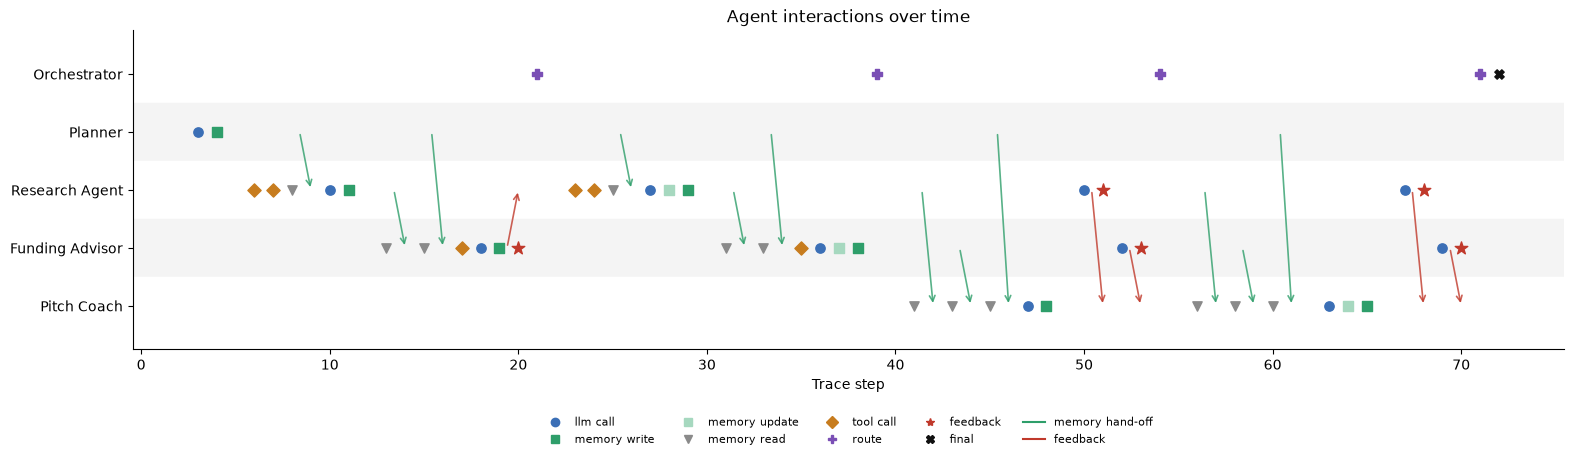

In [33]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


def plot_swimlanes(events: list[dict], save_to: Optional[Path] = None):
    lanes = ["Orchestrator", "Planner", "Research Agent", "Funding Advisor", "Pitch Coach"]
    y = {a: i for i, a in enumerate(reversed(lanes))}
    style = {"llm_call": ("o", "#3b6fb6"), "memory_write": ("s", "#2e9e6a"), "memory_update": ("s", "#a6d8bf"),"memory_read": ("v", "#8a8a8a"),
             "tool_call": ("D", "#c77c1e"), "route": ("P", "#7a4fb5"), "feedback": ("*", "#c0392b"),
             "final": ("X", "#111111")}
    fig, ax = plt.subplots(figsize=(max(10, len(events) * 0.22), 4.8))
    for i, a in enumerate(lanes):
        ax.axhspan(y[a] - 0.5, y[a] + 0.5, color="#f4f4f4" if i % 2 else "white", zorder=0)
    for e in events:
        if e["event"] in style and e["agent"] in y:
            m, c = style[e["event"]]
            ax.scatter(e["step"], y[e["agent"]], marker=m, color=c, s=90 if m == "*" else 45, zorder=3)
        if e["event"] in ("handoff", "feedback") and e.get("to_agent") in y:
            src = e.get("from_agent", e["agent"])
            if src in y:
                color = "#2e9e6a" if e["event"] == "handoff" else "#c0392b"
                ax.annotate("", xy=(e["step"], y[e["to_agent"]]), xytext=(e["step"] - 0.6, y[src]),
                            arrowprops=dict(arrowstyle="->", color=color, lw=1.2, alpha=0.8), zorder=2)
    ax.set_yticks(list(y.values()), list(y.keys()))
    ax.set_xlabel("Trace step")
    ax.set_title("Agent interactions over time")
    handles = [Line2D([], [], marker=m, color=c, linestyle="", label=k.replace("_", " ")) for k, (m, c) in style.items()]
    handles += [Line2D([], [], color="#2e9e6a", label="memory hand-off"), Line2D([], [], color="#c0392b", label="feedback")]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=5, frameon=False, fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    if save_to:
        fig.savefig(save_to, dpi=150, bbox_inches="tight")
    return fig


plot_swimlanes(tracer.events, tracer.run_dir / "swimlanes.png")
plt.show()

### 9c. Memory hand-off matrix and memory contents
How many memory items each agent pulled from each other agent, and what is in the shared memory.

In [34]:
def handoff_matrix(events: list[dict]):
    agents = ["Planner", "Research Agent", "Funding Advisor", "Pitch Coach"]
    counts = {(s, r): 0 for s in agents for r in agents}
    for e in events:
        if e["event"] == "handoff" and (e["from_agent"], e["to_agent"]) in counts:
            counts[(e["from_agent"], e["to_agent"])] += len(e["item_ids"])
    width = 17
    print("items retrieved  FROM (rows) -> BY (columns)\n")
    print(" " * width + "".join(a[:width - 2].ljust(width) for a in agents))
    for s in agents:
        print(s.ljust(width) + "".join(str(counts[(s, r)] or "-").ljust(width) for r in agents))


handoff_matrix(tracer.events)
print(f"\nShared memory: {len(memory.items)} items")
for m in memory.items:
    flag = " (superseded)" if m["superseded"] else ""
    print(f"  {m['id']} [{m['author']:<15} {m['kind']:<8} it={m['iteration']}]{flag} {m['text'][:100]}")

items retrieved  FROM (rows) -> BY (columns)

                 Planner          Research Agent   Funding Advisor  Pitch Coach      
Planner          -                12               8                10               
Research Agent   -                -                20               16               
Funding Advisor  -                -                -                10               
Pitch Coach      -                -                -                -                

Shared memory: 100 items
  M001 [Planner         plan     it=0] Map the clinical workflows and staffing models in representative rural primary-care clinics (triage 
  M002 [Planner         plan     it=0] What evidence is required to demonstrate clinical validity and safety for an AI triage assistant in 
  M003 [Planner         plan     it=0] What are the data sources available in rural clinics (paper, electronic health records, referrals), 
  M004 [Planner         plan     it=0] What interoperability standards and tec

### 9d. Narrative: how the agents arrived at the final output
Built directly from the trace log (no extra LLM call), so it reflects exactly what happened.

In [35]:
def narrate(events: list[dict]) -> str:
    out = ["# How the agents produced this pitch outline", ""]
    for e in events:
        a, ev = e["agent"], e["event"]
        if ev == "run_start":
            out.append(f"**Step {e['step']}.** The run started for domain *{e['domain']}*.")
        elif ev == "llm_call":
            out.append(f"**Step {e['step']}. {a}** — {e['summary']} ({e['seconds']} s). "
                       f"*Its stated reasoning:* {e['reasoning']}")
        elif ev == "handoff":
            out.append(f"**Step {e['step']}.** {a} retrieved {len(e['item_ids'])} item(s) written by "
                       f"{e['from_agent']} from shared memory ({', '.join(e['item_ids'])}).")
        elif ev == "tool_call":
            out.append(f"**Step {e['step']}.** {a} ran a web search for “{e['query']}” "
                       f"({e['n_results']} result(s)).")
        elif ev == "feedback":
            items = "; ".join(e.get("items") or []) or "no changes requested"
            out.append(f"**Step {e['step']}. Feedback from {a} to {e['to_agent']}:** {e['summary']}. {items}")
        elif ev == "route":
            out.append(f"**Step {e['step']}. Orchestrator routing:** {e['summary']} — {e['reason']}.")
        elif ev == "final":
            out.append(f"**Step {e['step']}.** {e['summary']} to `{e['path']}`.")
    return "\n\n".join(out)


narrative = narrate(tracer.events)
(tracer.run_dir / "trace_narrative.md").write_text(narrative, encoding="utf-8")
display(Markdown(narrative))

# How the agents produced this pitch outline



**Step 1.** The run started for domain *healthtech*.

**Step 3. Planner** — create work plan (prompt ~201 tokens) (20.9 s). *Its stated reasoning:* This plan prioritizes clinical validation, regulatory readiness, and practical integration into low-resource workflows because these are the gating factors for adoption in rural primary care. The Research Agent must deliver grounded workflow, data and validation inputs the Pitch Coach will translate into a credible clinical-evidence and go-to-market story. The Funding Advisor must align funding sources and timelines to the validation milestones so the pitch asks match investor and grant expectations. Founders should verify all eligibility, amounts and deadlines with funding programs directly (model knowledge - verify).

**Step 6.** Research Agent ran a web search for “healthtech market trends 2026” (0 result(s)).

**Step 7.** Research Agent ran a web search for “healthtech startups customers competitors” (0 result(s)).

**Step 9.** Research Agent retrieved 6 item(s) written by Planner from shared memory (M001, M003, M002, M005, M009, M004).

**Step 10. Research Agent** — market research (prompt ~579 tokens) (14.4 s). *Its stated reasoning:* I synthesized typical rural primary-care realities (staffing patterns, record mixes, device/connectivity constraints) and mapped practical integration touchpoints and technical/ethical requirements that an AI triage assistant must meet to be usable and safe. Recommendations prioritize minimum viable integrations, patient safety (auditability + escalation), and pragmatic evaluation designs feasible in low-resource settings. All operational and regulatory details vary by country and clinic—implementing teams should validate local system lists, legal requirements and stakeholder preferences before design or pilots. (model knowledge - verify)

**Step 14.** Funding Advisor retrieved 10 item(s) written by Research Agent from shared memory (M031, M022, M021, M023, M024, M025, M027, M026, M028, M029).

**Step 16.** Funding Advisor retrieved 4 item(s) written by Planner from shared memory (M006, M007, M008, M015).

**Step 17.** Funding Advisor ran a web search for “healthtech startup grants non-dilutive funding programs 2026” (0 result(s)).

**Step 18. Funding Advisor** — funding plan (prompt ~1189 tokens) (22.7 s). *Its stated reasoning:* Given the product (AI triage for rural primary care) and research insights (need for offline-first apps, mixed record environments, CHW/task-shifting integration, demand for explainability and ethics/regulatory readiness), an optimal early funding mix is: (A) non-dilutive grants and accelerator support to build a safety-first prototype and short pilots; (B) procurement pilots via MoH/district or NGO partners to secure real customers and recurring revenue pathways; and (C) small equity or convertible capital (angel/impact seed) to cover product development, clinical validation and to meet milestones required by larger implementer/grantors and VCs. Grants and donor pilots validate clinical safety and health outcomes without dilution; procurement pilots validate buyer economics and unlock scale-stage multilateral funding. Investors at pre-seed will expect a working MVP, a small clinical pilot (3–10 clinics), evidence of clinician acceptance, an ethical/regulatory plan, and basic unit-economics. Match each funding source to a clear milestone (MVP → pilot outcomes → implementation-ready product) and sequence asks so each milestone de-risks and opens the next funding source. Always verify eligibility, award ceilings and timelines with the funder/agency — funding programs change frequently.

**Step 20. Feedback from Funding Advisor to Research Agent:** sent 2 question(s) to Research Agent. Which country(ies) and regions are you planning to pilot in first (name the country or countries)? I will map country-specific donor solicitations, MoH digital health procurement pilots, and local investor activity.; What is your target pilot scale and timeline (number of clinics, CHWs, and a 6/12/18 month target)? This affects which grant windows and investor types to prioritize.

**Step 21. Orchestrator routing:** funding -> research — Funding Advisor asked Research for evidence.

**Step 23.** Research Agent ran a web search for “healthtech Which country(ies) and regions are you planning to pilot in first (name the country or countries)? I will map country-specific donor solicitations, MoH digital health procurement pilots, and local investor activity.” (0 result(s)).

**Step 24.** Research Agent ran a web search for “healthtech What is your target pilot scale and timeline (number of clinics, CHWs, and a 6/12/18 month target)? This affects which grant windows and investor types to prioritize.” (0 result(s)).

**Step 26.** Research Agent retrieved 6 item(s) written by Planner from shared memory (M001, M003, M002, M005, M009, M004).

**Step 27. Research Agent** — answer peer questions (prompt ~1272 tokens) (62.1 s). *Its stated reasoning:* Below are concise answers to the planner’s requests (M001–M005) to guide operational planning. All operational assertions should be verified with local partners and MoH offices before committing resources. (model knowledge - verify)

M001 — Clinical workflows & staffing models (high-level):
- Triage entry points: patient/guardian arrives at clinic or CHW triages household; initial screen often by a health assistant, nurse, or CHW using paper triage forms or registration desk. Severe-illness cues often recognized visually (breathing difficulty, convulsions) and via short symptom checklists. 
- Typical patient flow: registration (paper or simple digital), triage (vitals/quick symptom screen), clinician consultation (nurse/clinical officer), treatment/referral, pharmacy dispense and record in registers. CHWs identify and refer, often using paper referral slips or SMS. 
- Staffing ratios and hours: small rural clinics commonly staffed by 1–3 clinical staff during daytime; many close evenings/weekends or have on-call arrangements. CHW programs have many community-level volunteers or salaried community health extension workers with varying literacy/digital skills. 
- Connectivity & devices: intermittent/no network; a mixture of personal Android phones, occasional facility tablets, and paper registers. Power outages are common; solar chargers may exist in some facilities. 
- Minimum integration touchpoints for a triage assistant: offline-capable mobile app for triage; local storage for logs; ability to print or generate a simple referral slip (PDF/SMS); lightweight sync for district reporting or supervisory dashboards; simple CSV export/import and optional API to common EHRs (OpenMRS) and DHIS2 reporting. 

M003 — Data sources and legal/privacy constraints:
- Typical data sources: paper registers (outpatient / IMCI registers), referral slips, facility-held triage ledgers, partial EHR installations (OpenMRS variants), facility-level DHIS2 reporting, and CHW registers. 
- Legal/privacy constraints: regulations vary by country; requirements usually include data minimization, patient confidentiality, secure storage and controlled access. Secondary use of patient data for model development commonly requires ethics approval and data-sharing agreements; de-identification is necessary but may not be sufficient depending on jurisdiction. 
- Consent & administrative workflows required: informed consent processes for data capture and secondary use (often embedded in facility registration or separate research consent for pilots), MoH approvals for pilots using facility data, data-sharing agreements with clear retention and deletion policies, and local ethics/IRB clearance for model training or clinical evaluation. 

M002 — Evidence required & pragmatic study designs:
- Evidence required: clinical validity (sensitivity/specificity for identifying severe illness), safety (rate of missed severe cases), usability (task completion times, adherence to recommendations), and implementation outcomes (referral uptake, timeliness, workload impact). Regulatory or procurement bodies will want validation against local standard-of-care and demonstration there are safeguards to prevent harm. 
- Pragmatic study designs:
  - Phase 1 (feasibility/usability, 0–6 months): 5–10 clinics, mixed-methods usability testing, observe concordance between app vs clinician triage on simulated and real cases; endpoints: usability scores, time-to-triage, critical failure modes. 
  - Phase 2 (prospective validation, 6–12 months): cluster or stepped-wedge pilot across 20–50 clinics comparing app-assisted triage vs standard-of-care; endpoints: sensitivity for detecting severe illness requiring referral, referral appropriateness, adverse events; primary safety endpoint = missed severe illness rate. 
  - Phase 3 (outcomes/implementation, 12–18+ months): larger district-level evaluation testing outcomes (hospital admissions for severe illness, time-to-treatment, mortality where feasible), cost-effectiveness, and scalability metrics. Use mixed methods (quantitative clinical endpoints + qualitative acceptability). 

M005 — Competitive landscape & go-to-market levers:
- Competing products commonly include digital IMCI implementations, local EHR decision-support modules, and consumer triage apps adapted to clinic use. Key differentiators to emphasize: offline-first robustness, low-friction workflows for low-skill users, transparent decision logic and audit logs, local language and guideline alignment, and tight referral / supervisory feedback loops. 

M004 — Interoperability standards & technical constraints:
- Required technical support: Android-first mobile clients, offline-first data layer with conflict resolution and background sync, compact local models or rule engines to run triage logic offline, lightweight encryption at rest and in transit, and minimal dependency on continuous connectivity. 
- Interoperability: support for CSV import/export, simple RESTful APIs for integration with OpenMRS and DHIS2 where available, and HL7 FHIR where partners support it (but don’t assume FHIR will be available in all sites). Prioritize pragmatic file exchange and scheduled push/pull syncs with district servers. 

Practical next steps recommended (operational, not funding advice): map district-level MoH contacts in chosen pilot countries, run rapid device and connectivity audits in candidate clinics, obtain local ethics guidance early, and design a 6–12 month phased evaluation that prioritizes safety endpoints and operational feasibility. Verify all country-specific procurement and regulatory details with local partners and authorities, as these change frequently. (model knowledge - verify)

**Step 32.** Funding Advisor retrieved 10 item(s) written by Research Agent from shared memory (M051, M059, M049, M052, M053, M054, M055, M050, M056, M057).

**Step 34.** Funding Advisor retrieved 4 item(s) written by Planner from shared memory (M006, M007, M008, M015).

**Step 35.** Funding Advisor ran a web search for “healthtech startup grants non-dilutive funding programs 2026” (0 result(s)).

**Step 36. Funding Advisor** — funding plan (prompt ~1216 tokens) (65.2 s). *Its stated reasoning:* Recommended blended approach: combine non-dilutive prototype/pilot grants and implementer-led sub-awards to validate safety, usability and health outcomes in a small number of rural clinics, while raising a small pre-seed convertible round to cover software hardening (offline logic, logging, security), local staffing, regulatory/ethics costs and pilot operations. Sequence and milestones that unlock each source:

- Prototype grant / accelerator support (months 0–6): unlocks once you have a minimum viable offline app and basic usability testing. Use funds to finalize offline clinical logic, implement audit trails and prepare an evaluation protocol. (Foundations / accelerators)

- NGO/district pilot sub-award or ministry pilot procurement (months 4–12): unlocks after securing an MoU with clinic/district partners and IRB/ethics approvals; demonstrate safe operations in 2–6 clinics and basic outcome measures (triage agreement with clinicians, workflow integration). This provides operational validation and local buy-in necessary for scale procurement. (NGO / district procurement)

- Small pre-seed convertible note / SAFE (months 2–8): raise in parallel or immediately after early pilot results to fund expanded pilots, hire a clinical lead, and prepare regulatory documentation. Investors will expect predefined milestones: pilot MoU, initial clinical metrics, retention/usage metrics and a plan for procurement integration. (Angels / impact VCs)

- Scale funding (late seed / Series A): pursue after robust clinical validation, demonstrated value to purchasers (districts/NGOs), and early procurement commitments. Use procurement pilots and NGO partnerships as commercial traction for larger rounds.

Business model & GTM summary:
- Customer segments: small rural primary-care clinics/health posts (clinic-level licenses or device+support), district health offices (district-level deployments via procurement), CHW programs (per-CHW subscriptions or per-referral fee), NGOs/donors (program-level contracts) and national health ministries (procurement contracts). (M054, M055, M056)
- Buyer economics: districts/NGOs purchase on behalf of clinics and value predictable per-clinic/per-CHW costs plus training and support. Buyers care about staff time saved, reductions in adverse events and simpler referral workflows. Provide TCO scenarios (software subscription + deployment support + optional hardware). (model knowledge - verify)
- Procurement pathways: 1) small pilots via district innovation units or NGO programs, 2) donor-funded scale via NGO procurement, 3) government tenders for digital health or eHealth frameworks. A pilot → evidence → procurement pathway is typical; local partnerships accelerate acceptance. (M050, M057)
- Pricing / reimbursement hypotheses: start with low monthly subscription per clinic or per active CHW (or a per-referral fee where acceptable), plus a one-time deployment/training fee. For government buyers, price bundles as multi-year service contracts with SLAs and support. Consider outcome-based pilots with partial payment tied to agreed KPIs with NGOs/districts. (model knowledge - verify)
- Pilot-to-scale route: run a rigorous pilot with operational metrics (uptime in offline settings, clinician adherence to recommendations, referral completion rates), plus clinical validation for safety. Use NGO/district pilots to secure procurement references, then pursue district-level rollouts or national procurement frameworks. Ensure HMIS integration options (CSV import, minimal APIs, OpenMRS/DHIS2 compatibility) and strong data governance to meet procurement and regulatory expectations. (M049, M050, M052, M053)

Caveats and next steps:
- All program eligibility, award sizes and timelines must be verified directly with funders, ministries and investors as these change frequently.
- Prioritize securing at least one local pilot partner (district or NGO) and IRB/ethics approvals early — these are gating items for most donors and government pilots.
- Prepare two parallel asks: a non-dilutive pilot grant (or accelerator slot) to fund evaluation and an investor pitch for a small convertible note to fund operational scale-up if the pilot is successful.

**Step 39. Orchestrator routing:** funding -> pitch_coach — funding plan complete.

**Step 42.** Pitch Coach retrieved 8 item(s) written by Research Agent from shared memory (M064, M052, M050, M049, M053, M054, M055, M051).

**Step 44.** Pitch Coach retrieved 5 item(s) written by Funding Advisor from shared memory (M070, M074, M076, M073, M075).

**Step 46.** Pitch Coach retrieved 5 item(s) written by Planner from shared memory (M014, M010, M015, M013, M001).

**Step 47. Pitch Coach** — draft outline (prompt ~1570 tokens) (80.2 s). *Its stated reasoning:* This 12-slide outline maps directly to the Planner requirements (solution description, integration & deployment, business model & reimbursement, data & privacy, and clinical workflow mapping) and synthesizes the Research Agent insights (target users, offline-first norm, mixed paper/EHR environments, need for explainability/audit trails, task-shifting) and the Funding Advisor recommendations (pilot design, funding routes and stage). Each slide cites the specific peer inputs used so every factual claim is grounded in those inputs. Where the founder must supply specifics (team, traction, exact ask, country/regulatory details, device inventory, pricing), I left explicit placeholders and flagged them in gaps_in_inputs. Note: verify any local regulatory or procurement details with the relevant authorities and funding bodies before committing to timelines or eligibility.

**Step 50. Research Agent** — peer review of outline (prompt ~2854 tokens) (50.8 s). *Its stated reasoning:* I reviewed the outline against the research-area assertions you provided. The core market/operational claims are consistent with domain knowledge but several are stated as facts without local validation or citations. Specific points: - Offline-first and mixed paper+EHR workflows: This is consistent with my summary (confidence high) but should be presented as commonly observed in many low-resource rural settings rather than universal — label as model knowledge - verify unless you can cite local assessments or partners. - Task-shifting / CHW-driven design: Correct and appropriately emphasized (model knowledge - verify). Make explicit that workflows vary by country and program. - Explainability / audit trails / regulatory scrutiny: These are growing trends (confidence medium) but regulatory requirements and the weight given to explainability differ by jurisdiction; avoid implying a uniform regulatory roadmap. - Customers & procurement: The customer segments listed are appropriate, and pilots via foundations/district bodies is a plausible go-to-market path (model knowledge - verify). However procurement realities and timelines vary; don’t state procurement routes as certain. - Competitors & risks: The competitors listed are reasonable examples (digital IMCI implementations, OpenMRS front-ends, consumer triage bots) but the deck should explicitly map overlap and differentiation and avoid implying those competitors are direct substitutes without validation. - Pilot size and funding recommendations: Reasonable but context-dependent — present as hypotheses and ask investors for input or cite examples. Overall the deck is founder-ready in structure and content but needs modest rewording and explicit labeling of assumptions/uncertainties. Where assertions are based on general domain knowledge rather than specific cited research, mark them as model knowledge - verify and commit to validating them with on-the-ground partners or references. Also verify any funding program eligibility/amounts/deadlines with the programs themselves.

**Step 51. Feedback from Research Agent to Pitch Coach:** approved (score 4/5). Replace absolute phrasing with hedged language or cite local evidence (e.g., change "are the practical norm" → "are commonly required" or add a source). Label these as model knowledge - verify where you currently have no citation.; Mark pilot sizing ("2–6 clinics") clearly as a working hypothesis with rationale (cost, operational complexity, statistical power if claiming impact) or provide past benchmarks if available.; Add a short slide note (or slide appendix) stating that regulatory requirements differ by country and that the team will validate local expectations with national regulators and ethics committees prior to pilot — don’t imply a one-size-fits-all regulatory path.; On the competitors slide, add brief, sourced comparisons: which features overlap (offline operation, decision rules, referral slips) and which are differentiators (hybrid rules+ML, auditability, CHW-focused UX). If you lack citations, label statements as model knowledge - verify and commit to rapid competitor intelligence work prior to fundraising.; Soften claims that explainability/audit trails will be sufficient for clinician trust or medico-legal protection. Instead, state they’re necessary mitigations and list complementary adoption activities (training, supervision, local validation).

**Step 52. Funding Advisor** — peer review of outline (prompt ~2867 tokens) (55.1 s). *Its stated reasoning:* The deck's stated stage (Pre-seed → Pilot) and the high-level use-of-funds align with the funding channels you recommended (foundations/GRANTS, district pilots, NGO subawards, accelerators, early-stage investors). The narrative appropriately frames funders' expectations around measurable clinical impact, de-risking, and procurement-readiness. However, to be credible to the specific funders listed, the funding ask slide needs more granularity: an itemised budget and unit costs, clear milestones and go/no-go criteria, a summarized pilot protocol with endpoints and data collection plans, and explicit mapping of which funder/instrument will be asked for which amount or support. Funders (and procurement offices) routinely expect those elements to judge feasibility and value-for-money; without them the ask appears underspecified. Model knowledge - verify: include device, training, and ethics/regulatory cost lines and a contingency (these are common cost drivers in rural pilot budgets). Also verify eligibility, award sizes and deadlines directly with target programs because funding mechanisms change frequently.

**Step 53. Feedback from Funding Advisor to Pitch Coach:** requested changes (score 3/5). Specify the funding ask (or at least present 2–3 realistic ask scenarios) and include an itemised use-of-funds budget with major line items and unit costs (product dev, devices, field ops, training, M&E / data collection, ethics/regulatory, data security, overhead, and contingency).; Add a 6–12 month timeline with concrete milestones and go/no-go decision gates tied to measurable outcomes (e.g., target reduction in missed urgent cases, referral rate change, data completeness thresholds).; Include a compact pilot protocol summary: sample size or clinic count justification (your 2–6 clinics), primary and secondary endpoints, data collection instruments, who collects data, and how blinded/adjudicated outcomes will be assessed.; Map each recommended funder type to the exact ask/instrument you will pursue (example: foundation proof-of-concept grant for X months and $A to cover pilot ops and M&E; accelerator cohort for $B non-dilutive support + mentorship; district pilot procurement contract for a scoped implementation) and label these as intentions to verify with each program.; Add explicit cost lines and descriptions for: device procurement and management; on-site training and refresher sessions; local field staff salaries / per-diem; travel and allowances; M&E/data collection and analysis; ethics/regulatory submission costs; and an IT/data-security/compliance budget.; State procurement-readiness metrics and buyer economics you will demonstrate in the pilot (e.g., per-patient or per-facility cost, expected clinician time-savings, escalation/referral accuracy targets) so districts/ministry buyers can assess value.; Attach or plan to obtain partner commitments (MOUs/LOIs) from clinics, CHW programs, or a district health office, and show these in the slide or an appendix.; Add a short paragraph on expected next-stage funding needs and trigger conditions for pursuing dilutive capital (seed investors/angels) after a successful pilot — include runway estimates or amounts to be confirmed.; Include an explicit note to verify eligibility, award sizes and deadlines with specific funders/programs before applying (funding programs change often).

**Step 54. Orchestrator routing:** peer_review -> pitch_coach — 9 change request(s) to address.

**Step 57.** Pitch Coach retrieved 8 item(s) written by Research Agent from shared memory (M064, M052, M050, M049, M053, M063, M062, M061).

**Step 59.** Pitch Coach retrieved 5 item(s) written by Funding Advisor from shared memory (M070, M074, M076, M073, M075).

**Step 61.** Pitch Coach retrieved 5 item(s) written by Planner from shared memory (M014, M010, M015, M013, M001).

**Step 63. Pitch Coach** — revise outline (prompt ~3488 tokens) (82.4 s). *Its stated reasoning:* I synthesised the Planner's technical and deployment requirements, the Research Agent's constraints around data quality, mixed records and offline operation, and the Funding Advisor's specific fundraising and procurement-readiness requests. The output preserves the original product narrative (offline-first hybrid rules+ML triage assistant for nurse/CHW workflows) and adds the detailed pilot protocol, timeline with measurable go/no-go gates, funding scenarios and an itemised set of cost lines requested by peers. Monetary figures and unit-costs are presented as illustrative 'model knowledge - verify' because the project materials did not include local prices, salaries or exact award sizes — founders must confirm these before applying. The slide evidence fields cite the agent inputs used so the founder can trace back which research insights support each element.

**Step 67. Research Agent** — peer review of outline (prompt ~2861 tokens) (56.3 s). *Its stated reasoning:* From a research/field‑validation perspective the overall outline is well structured and addresses the right high‑level issues (offline operation, mixed workflows, explainability, audit trails). However, several market and outcome claims are stated as facts without explicit sourcing and key trial design elements are underspecified. The proposed pilot scale (2–6 clinics) can be appropriate for feasibility and safety signal detection, but it is unlikely to provide definitive evidence of reduced missed urgent cases unless accompanied by a power calculation and realistic baseline assumptions. Regulatory/procurement assertions and cost figures vary by country and should be verified with local partners and up‑to‑date vendor/funder information. I recommend the requested changes above before calling the deck founder‑ready for funder submissions that claim clinical impact or procurement readiness.

**Step 68. Feedback from Research Agent to Pitch Coach:** requested changes (score 3/5). Explicitly label market/operational claims that come from general domain knowledge as 'model knowledge - verify' in speaker notes (e.g., offline-first being the practical norm; common use of mixed paper + OpenMRS/DHIS2).; Replace any definitive outcome language ('reduce missed urgent cases', 'procurement‑ready') with hypothesis/objective language in the pitch (e.g., 'aim to reduce… to be evaluated in pilot').; Add a short statistical appendix / slide or speaker note with: (a) baseline rate assumptions for the primary endpoint (missed urgent cases), (b) a justification or calculation for the proposed sample size (or a statement that this pilot is feasibility/signal‑finding and not powered for effectiveness), and (c) expected effect size the pilot is designed to detect (or state it is not powered).; Define numeric go/no‑go criteria and explain how they were chosen (e.g., data completeness ≥ X%, adverse event rate ≤ Y per 1,000 encounters). If exact numbers are unknown, state that thresholds will be set a priori with the clinical lead and ethics board.; Specify the safety monitoring plan and independent review process: what constitutes a safety signal, who will review (blinded clinical reviewer or DSMB), and what operational steps will be taken if a signal is detected.; Replace placeholder funding amounts and unit costs with verified quotes or clearly label them as illustrative 'model knowledge - verify' and commit to updating before any funder submission.; Qualify regulatory/procurement pathway claims: add a note that national medical device/clinical decision support regulations and procurement rules vary, and that the team will verify requirements and timelines with each target district/ministry before pilot launch (model knowledge - verify).; If possible, include at least one citation or local partner statement (MOUs/LOIs) that supports claims about workflow realities (paper + EHR, CHW triage role) for the specific country/region targeted by the pilot; otherwise flag these as assumptions to be validated during site selection.

**Step 69. Funding Advisor** — peer review of outline (prompt ~2874 tokens) (54.1 s). *Its stated reasoning:* The deck's narrative, pilot design (2–6 clinics), timeline and funder targeting align well with the recommended pre-seed → pilot stage and the types of funders you advocated (foundations, district procurement, NGOs, accelerators, then investors). However, credibility with those funders depends on concrete, justified budget asks and a clear mapping of ask → deliverables → procurement-readiness outcomes. Right now the funding slide and use-of-funds lines mostly contain placeholders and high-level categories; that is insufficient for grant reviewers, procurement officers or implementing NGOs, who will ask for unit costs, partner commitments, and a per-site/patient cost model. Fixing the requested changes will make the funding ask credible and aligned to the recommended funder types. Always verify eligibility, award sizes and deadlines directly with target funders (funding programs change often).

**Step 70. Feedback from Funding Advisor to Pitch Coach:** requested changes (score 2/5). Replace all 'model knowledge - verify' placeholders with concrete, evidence-backed figures and cite supporting sources (vendor quotes, past project budgets, or funder award examples). If you use my general knowledge for numbers, label them 'model knowledge - verify' and flag them for confirmation.; Provide a detailed, itemised budget per scenario (A/B/C) including: personnel (roles, FTE %, local rates), local partner/sub-award, device procurement (unit cost × quantity × shipping/taxes), consumables, pulse oximeters (unit costs), training (trainer days, per diems, materials), travel & accommodation, field research officer time, M&E & data analysis, ethics/IRB fees, data hosting & security/compliance, contingency (suggest ~10–15% — model knowledge - verify), and overhead/subcontract management fees.; Add a per-site and per-patient cost table (with assumptions: expected encounters per month/site) so you can show buyer economics and compare expected per-patient cost vs current pathway. State all assumptions clearly and mark anything that is estimated as 'model knowledge - verify'.; For each funding scenario, map to 2–3 concrete funder program examples or types and state expected award ranges or typical instruments (grant, contract, accelerator stipend, equity) — verify award sizes and eligibility with the funder before applying.; Include line items and timeline linkage for the go/no-go gates (e.g., budget reserved for 3-month interim blinded safety review, independent statistician or DSMB, contingency to run extra training if data completeness is below threshold).; Show evidence of partner commitments (draft MOUs/LOIs) in the appendix or state when they will be secured; funders will treat the ask as higher-risk without named partners.; Add a short note in the funding slide explaining what deliverables each funder will receive (pilot report, data extracts, procurement-readiness dossier, capacity-building deliverables) and how those deliverables align to the funder's goals.

**Step 71. Orchestrator routing:** peer_review -> finalize — review round limit reached; remaining feedback listed in trace.

**Step 72.** outline with 12 slides saved to `runs/20261108_235520_healthtech/pitch_outline.md`.

### 9e. Per-agent contribution summary

In [36]:
def contribution_summary(events: list[dict]):
    agents = ["Planner", "Research Agent", "Funding Advisor", "Pitch Coach", "Orchestrator"]
    print(f"{'Agent':<16}{'LLM calls':>10}{'LLM secs':>10}{'mem writes':>12}{'mem reads':>11}{'feedback':>10}")
    for a in agents:
        ev = [e for e in events if e["agent"] == a]
        print(f"{a:<16}{sum(e['event'] == 'llm_call' for e in ev):>10}"
              f"{sum(e.get('seconds', 0) for e in ev if e['event'] == 'llm_call'):>10.1f}"
              f"{sum(len(e['item_ids']) for e in ev if e['event'] == 'memory_write'):>12}"
              f"{sum(e['event'] == 'memory_read' for e in ev):>11}"
              f"{sum(e['event'] == 'feedback' for e in ev):>10}")


contribution_summary(tracer.events)
print(f"\nAll artifacts for this run are in: {tracer.run_dir}/")
for p in sorted(tracer.run_dir.iterdir()):
    print("  -", p.name)

Agent            LLM calls  LLM secs  mem writes  mem reads  feedback
Planner                  1      20.9          20          0         0
Research Agent           4     183.6          41          2         2
Funding Advisor          4     197.1          15          4         3
Pitch Coach              2     162.6          24          6         0
Orchestrator             0       0.0           0          0         0

All artifacts for this run are in: runs/20261108_235520_healthtech/
  - final_state.json
  - memory.json
  - pitch_outline.md
  - swimlanes.png
  - trace.jsonl
  - trace_narrative.md
  - workflow_graph.mmd


## 10. Try another domain (optional)

In [ ]:
# final_state2, tracer2, memory2, _ = run_accelerator("fintech", "Seed-stage SME cash-flow forecasting tool")
# display(Markdown(final_state2["final_markdown"]))